In [1]:
from pathlib import Path

import cv2
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

CONFIG_PATH = Path("F:/ZPB/eyepacs-dr-classification/configs/config.yaml")

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

images_dir = Path(config["paths"]["images_dir"])
labels_csv = Path(config["paths"]["labels_csv"])

labels_df = pd.read_csv(labels_csv)
labels_df["image_path"] = labels_df["image"].apply(lambda name: images_dir / f"{name}.jpeg")

print("OpenCV:", cv2.__version__)
print("Liczba etykiet:", len(labels_df))
print("images_dir exists:", images_dir.exists())
print("labels_csv exists:", labels_csv.exists())

OpenCV: 4.13.0
Liczba etykiet: 35126
images_dir exists: True
labels_csv exists: True


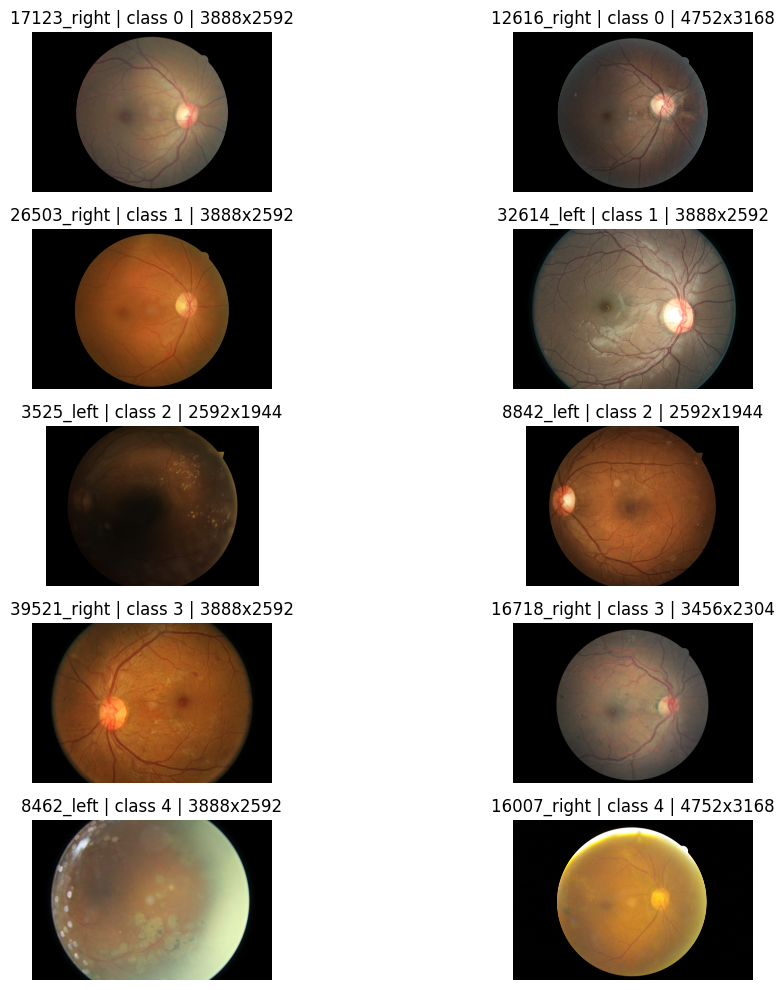

In [6]:
sample_parts = []

for level, group in labels_df.groupby("level"):
    sample_parts.append(group.sample(2, random_state=42))

sample_df = pd.concat(sample_parts).reset_index(drop=True)

plt.figure(figsize=(12, 10))

for i, (_, row) in enumerate(sample_df.iterrows(), start=1):
    image = Image.open(row["image_path"])

    plt.subplot(5, 2, i)
    plt.imshow(image)
    plt.title(f'{row["image"]} | class {row["level"]} | {image.size[0]}x{image.size[1]}')
    plt.axis("off")

plt.tight_layout()
plt.show()

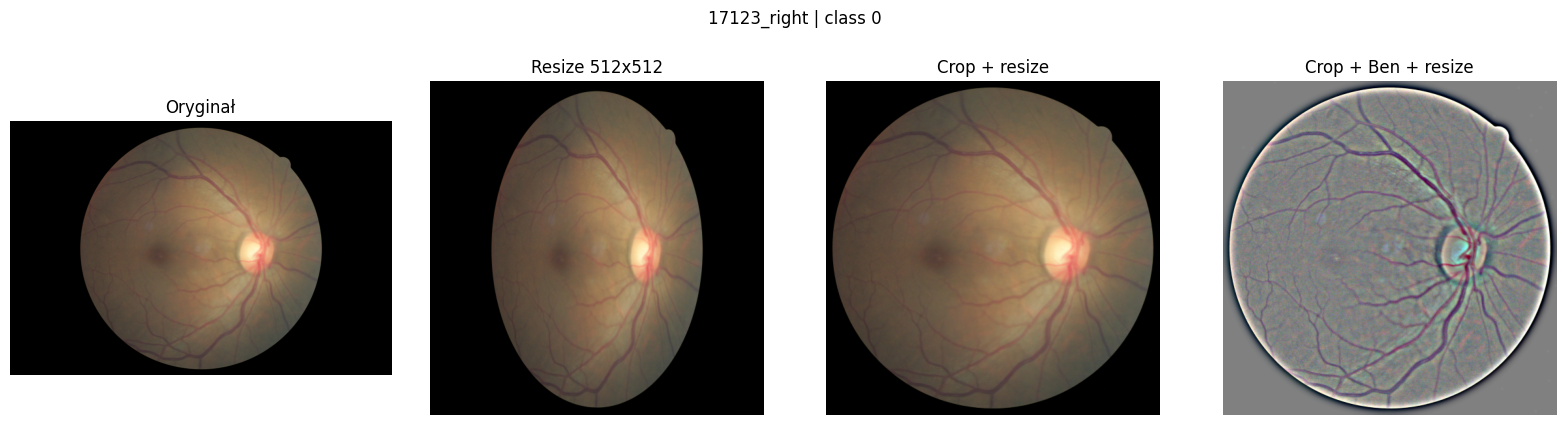

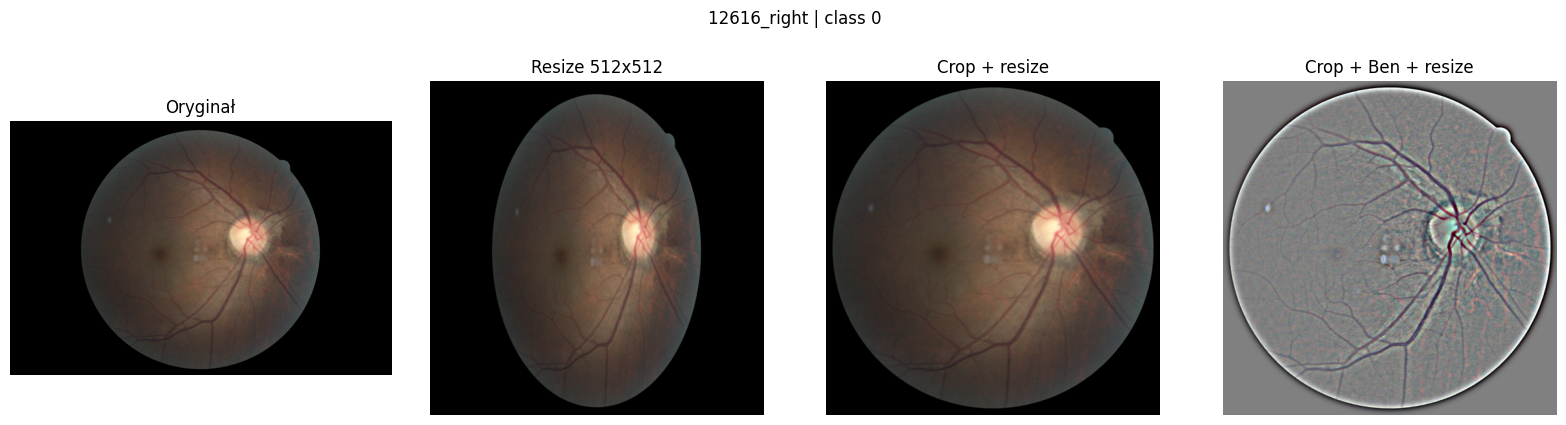

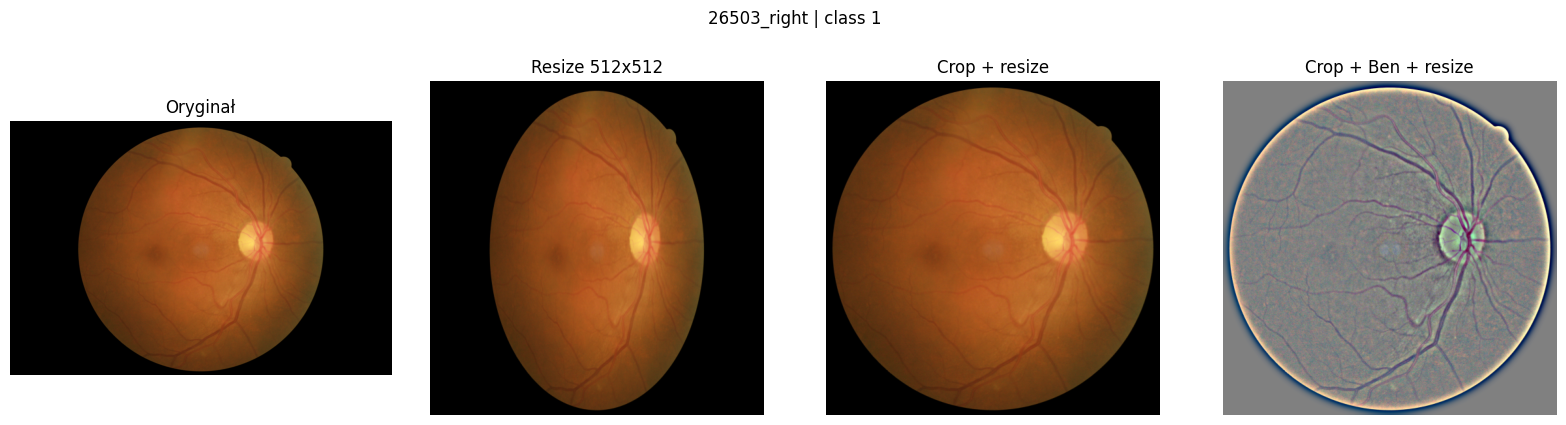

In [7]:
def load_rgb_image(path):
    image_bgr = cv2.imread(str(path))

    if image_bgr is None:
        raise ValueError(f"Nie udało się wczytać obrazu: {path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    return image_rgb


def crop_black_border(image, threshold=10, margin=0.02):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    mask = gray > threshold

    if not mask.any():
        return image

    y_indices, x_indices = mask.nonzero()

    y_min, y_max = y_indices.min(), y_indices.max()
    x_min, x_max = x_indices.min(), x_indices.max()

    height, width = image.shape[:2]

    margin_y = int((y_max - y_min) * margin)
    margin_x = int((x_max - x_min) * margin)

    y_min = max(y_min - margin_y, 0)
    y_max = min(y_max + margin_y, height - 1)
    x_min = max(x_min - margin_x, 0)
    x_max = min(x_max + margin_x, width - 1)

    return image[y_min:y_max + 1, x_min:x_max + 1]


def resize_image(image, size=512):
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)


def ben_graham_correction(image, sigma=30):
    blurred = cv2.GaussianBlur(image, (0, 0), sigma)
    corrected = cv2.addWeighted(image, 4, blurred, -4, 128)
    return corrected


def preprocess_variants(path, size=512):
    original = load_rgb_image(path)

    resized = resize_image(original, size)

    cropped = crop_black_border(original)
    cropped_resized = resize_image(cropped, size)

    ben_corrected = ben_graham_correction(cropped)
    ben_resized = resize_image(ben_corrected, size)

    return original, resized, cropped_resized, ben_resized


rows_to_show = sample_df.head(3)

for _, row in rows_to_show.iterrows():
    original, resized, cropped_resized, ben_resized = preprocess_variants(row["image_path"], size=512)

    images = [
        ("Oryginał", original),
        ("Resize 512x512", resized),
        ("Crop + resize", cropped_resized),
        ("Crop + Ben + resize", ben_resized)
    ]

    plt.figure(figsize=(16, 4))

    for i, (title, image) in enumerate(images, start=1):
        plt.subplot(1, 4, i)
        plt.imshow(image)
        plt.title(title)
        plt.axis("off")

    plt.suptitle(f'{row["image"]} | class {row["level"]}', y=1.05)
    plt.tight_layout()
    plt.show()

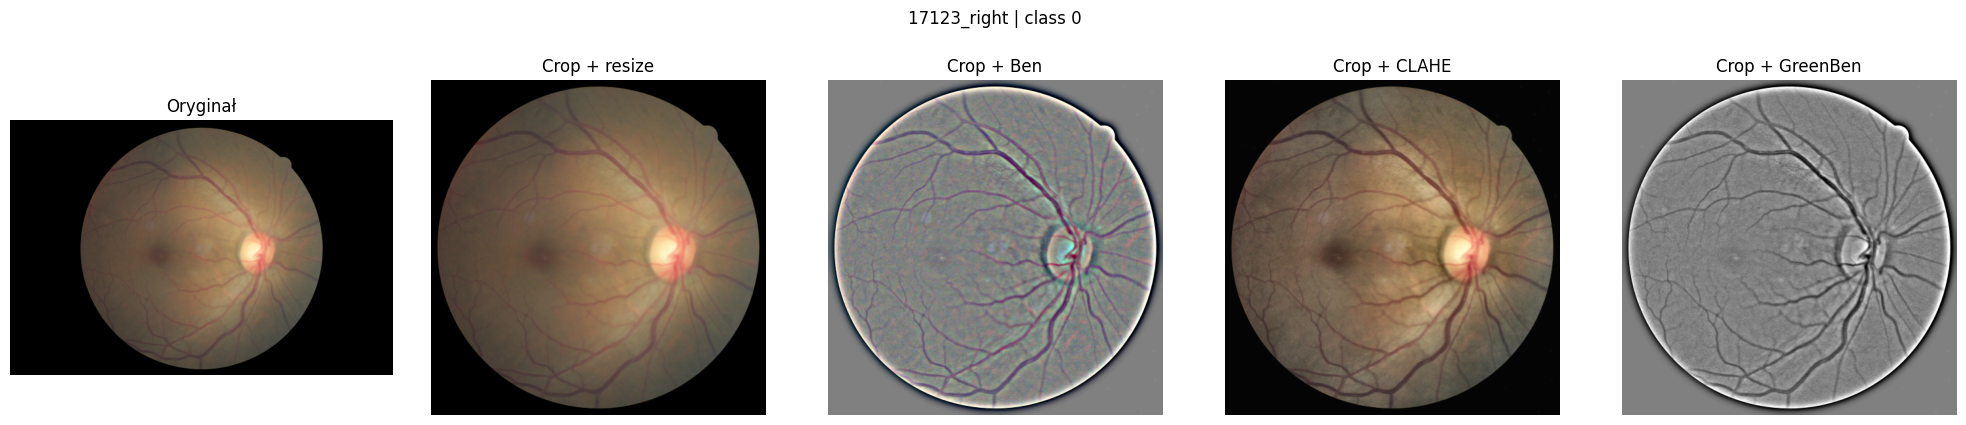

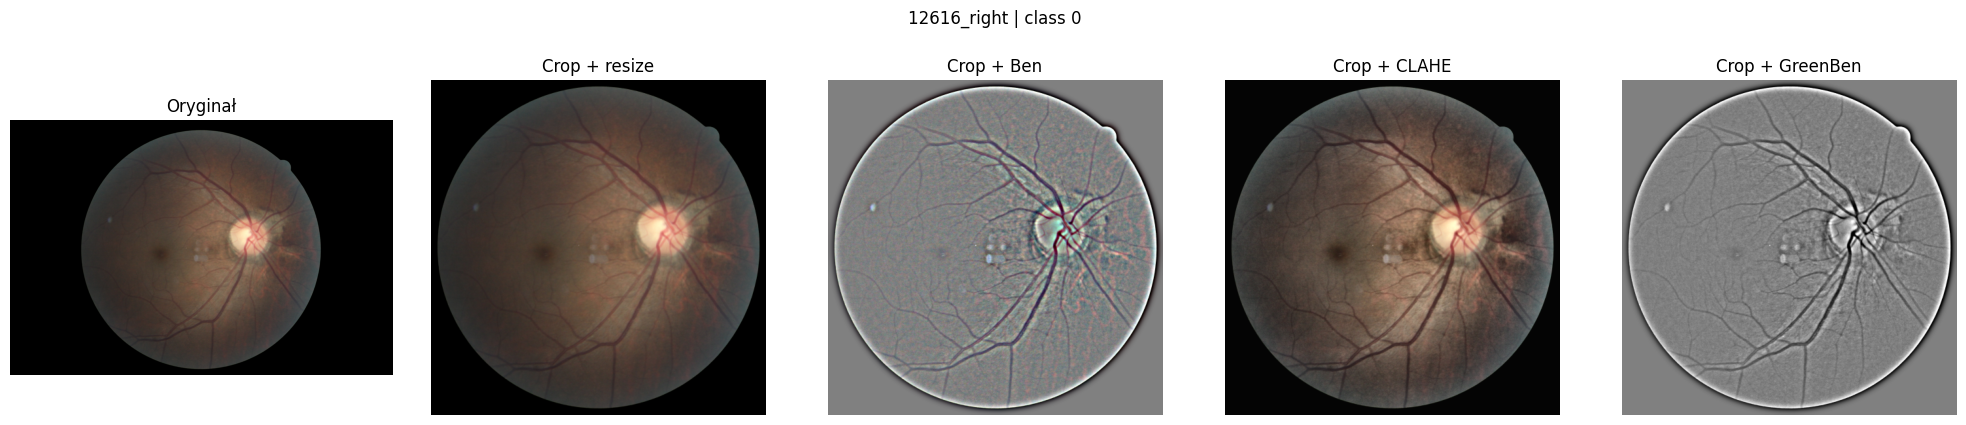

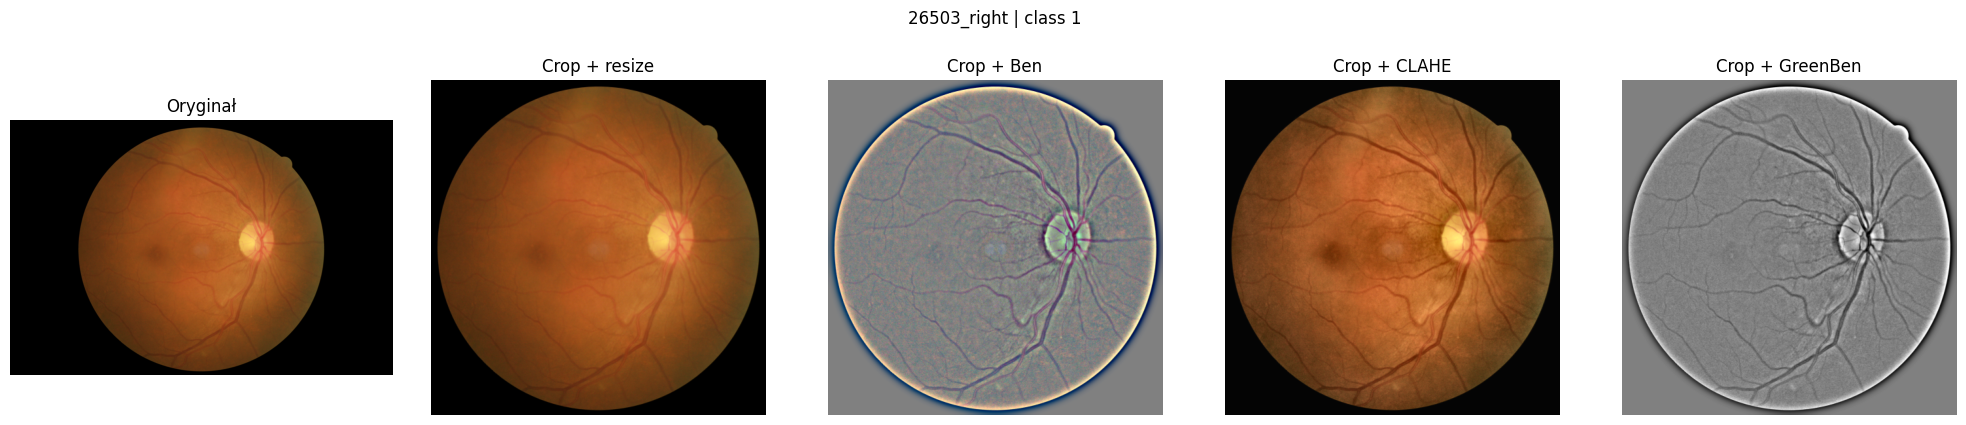

In [11]:
def load_rgb_image(path):
    image_bgr = cv2.imread(str(path))

    if image_bgr is None:
        raise ValueError(f"Nie udało się wczytać obrazu: {path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    return image_rgb


def crop_black_border(image, threshold=10, margin=0.02):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    mask = gray > threshold

    if not mask.any():
        return image

    y_indices, x_indices = mask.nonzero()

    y_min, y_max = y_indices.min(), y_indices.max()
    x_min, x_max = x_indices.min(), x_indices.max()

    height, width = image.shape[:2]

    margin_y = int((y_max - y_min) * margin)
    margin_x = int((x_max - x_min) * margin)

    y_min = max(y_min - margin_y, 0)
    y_max = min(y_max + margin_y, height - 1)
    x_min = max(x_min - margin_x, 0)
    x_max = min(x_max + margin_x, width - 1)

    return image[y_min:y_max + 1, x_min:x_max + 1]


def resize_image(image, size=512):
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)


def ben_graham_correction(image, sigma=30):
    blurred = cv2.GaussianBlur(image, (0, 0), sigma)
    corrected = cv2.addWeighted(image, 4, blurred, -4, 128)
    return corrected


def clahe_correction(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    l_channel_clahe = clahe.apply(l_channel)

    lab_clahe = cv2.merge([
        l_channel_clahe,
        a_channel,
        b_channel
    ])

    image_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    return image_clahe


def green_ben_correction(image, sigma=30):
    green_channel = image[:, :, 1]

    blurred = cv2.GaussianBlur(green_channel, (0, 0), sigma)
    corrected_green = cv2.addWeighted(green_channel, 4, blurred, -4, 128)

    green_ben_rgb = cv2.merge([
        corrected_green,
        corrected_green,
        corrected_green
    ])

    return green_ben_rgb


def preprocess_crop_resize(path, size=512):
    image = load_rgb_image(path)
    image = crop_black_border(image)
    image = resize_image(image, size)
    return image


def preprocess_crop_ben_resize(path, size=512):
    image = load_rgb_image(path)
    image = crop_black_border(image)
    image = ben_graham_correction(image)
    image = resize_image(image, size)
    return image


def preprocess_crop_clahe_resize(path, size=512):
    image = load_rgb_image(path)
    image = crop_black_border(image)
    image = clahe_correction(image)
    image = resize_image(image, size)
    return image


def preprocess_crop_greenben_resize(path, size=512):
    image = load_rgb_image(path)
    image = crop_black_border(image)
    image = green_ben_correction(image)
    image = resize_image(image, size)
    return image


rows_to_show = sample_df.head(3)

for _, row in rows_to_show.iterrows():
    original = load_rgb_image(row["image_path"])
    crop_resize = preprocess_crop_resize(row["image_path"], size=512)
    crop_ben_resize = preprocess_crop_ben_resize(row["image_path"], size=512)
    crop_clahe_resize = preprocess_crop_clahe_resize(row["image_path"], size=512)
    crop_greenben_resize = preprocess_crop_greenben_resize(row["image_path"], size=512)

    images = [
        ("Oryginał", original),
        ("Crop + resize", crop_resize),
        ("Crop + Ben", crop_ben_resize),
        ("Crop + CLAHE", crop_clahe_resize),
        ("Crop + GreenBen", crop_greenben_resize)
    ]

    plt.figure(figsize=(20, 4))

    for i, (title, image) in enumerate(images, start=1):
        plt.subplot(1, 5, i)
        plt.imshow(image)
        plt.title(title)
        plt.axis("off")

    plt.suptitle(f'{row["image"]} | class {row["level"]}', y=1.05)
    plt.tight_layout()
    plt.show()